# Butter-stick sculpture: can the monthly-mean radial bar chart be carved from 3 sticks?

**The brief.** Competition rules issue **3 standard US East-Coast (Elgin) butter sticks**. Slice each stick into **4 slices** (12 slices total) and use **one slice per month** to form the 12 bars of the *mean cold-storage stocks by month* radial chart (the typical-year chart at the end of `butter_cold_storage.ipynb`).

**Assumptions** (all are parameters in the next cell, so change them and re-run):
- Each month's bar is carved from *its own* slice (no sharing or stacking slices, no melting and re-moulding).
- A bar is an annular sector (a fat "slice of a ring"), flat on top, as thick as the slice. Bar length ∝ mean stocks, starting from an inner radius `R0` so the bars are not needle-thin at the centre.
- January points up, months run clockwise, as in the original chart.

**Plan:** load the means → sanity-check the stick size → compare two ways of slicing → solve for the largest chart that fits → verify every month → export **1:1 printable templates**.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.patches import Polygon, Rectangle
from IPython.display import Markdown, display
from pathlib import Path

# ---- the butter (inches). MEASURE YOUR SPONSOR'S STICKS and edit these. ----
STICK_L, STICK_W, STICK_H = 4.75, 1.25, 1.25   # Elgin / East-Coast stick: long, thin, square cross-section
STICK_MASS_G   = 113.4                          # 4 oz
BUTTER_DENSITY = 0.911                          # g/cm^3 (cold butter ~0.91)
N_STICKS, SLICES = 3, 4

# ---- cutting / carving constraints ----
KERF        = 0.02    # in, material lost per cut (wire / floss / thin knife)
EDGE_MARGIN = 0.05    # in, keep this much clear of the slice edge (hand room, crumbling)
MIN_FEAT    = 0.30    # in, narrowest part of any bar (about as wide as the slice is thick)
MAX_R       = 3.50    # in, so the assembled chart still prints 1:1 on a Letter page with labels
PITCH       = 30.0    # deg between months

FIGS = Path("figures"); FIGS.mkdir(exist_ok=True)
MONTHS = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

## 1. The data: mean end-of-month stocks across all years
Same cached USDA NASS file the first notebook uses. The mean per calendar month is taken over every year available (the original notebook's "all years" mean).

In [2]:
raw = pd.read_csv("data/raw/butter_cold_storage_raw.csv", dtype=str, keep_default_na=False)
raw["mlb"]   = pd.to_numeric(raw["Value"].str.replace(",", "", regex=False), errors="coerce") / 1e6
raw["month"] = raw["reference_period_desc"].str.extract(r"^END OF ([A-Z]{3})$")[0].str.title()
raw = raw.dropna(subset=["mlb", "month"])
mean_m = raw.groupby("month")["mlb"].mean().reindex(MONTHS)
VALS = mean_m.values
print(f"{raw['year'].nunique()} years of data")
print(mean_m.round(1).to_string())
assert abs(mean_m["Jul"] - 224.3) < 0.1 and abs(mean_m["Dec"] - 127.2) < 0.1   # matches the radial chart in the first notebook

112 years of data
month
Jan    135.0
Feb    144.7
Mar    150.9
Apr    162.3
May    184.1
Jun    212.9
Jul    224.3
Aug    215.5
Sep    198.7
Oct    170.9
Nov    140.0
Dec    127.2


## 2. Sanity check: is the stick geometry believable?
If the dimensions and density reproduce the 4 oz label weight, the dimensions are right.

In [3]:
vol_in3 = STICK_L * STICK_W * STICK_H
mass = vol_in3 * 16.387 * BUTTER_DENSITY
print(f"Stick volume {vol_in3:.2f} in^3 -> {mass:.1f} g predicted vs {STICK_MASS_G} g label ({100*(mass/STICK_MASS_G-1):+.1f}%)")
assert abs(mass / STICK_MASS_G - 1) < 0.05

Stick volume 7.42 in^3 -> 110.8 g predicted vs 113.4 g label (-2.3%)


## 3. Two ways to cut a stick into 4 slices
| | Cut direction | Each slice is | Plan face available for a bar |
|---|---|---|---|
| **A: cross-cuts** | across the length, 4 short chunks | 1.18 × 1.25 × 1.25 in | a **1.25 × 1.25 in** square |
| **B: lengthwise** | along the length, 4 thin planks | 4.75 × 1.25 × 0.30 in | a long **4.75 × 1.25 in** plank |

Same volume either way; the question is which *shape* of slice lets the bars be longest. A bar for the biggest month (July) has to fit inside its slice's face.

In [4]:
t_B = (STICK_W - (SLICES - 1) * KERF) / SLICES          # plank thickness
t_A = (STICK_L - (SLICES - 1) * KERF) / SLICES          # chunk thickness
OPTIONS = {
    "A: cross-cuts": dict(face=(STICK_W, STICK_H), thick=t_A),
    "B: lengthwise": dict(face=(STICK_L, STICK_H), thick=t_B),
}
for k, o in OPTIONS.items():
    print(f"{k}: face {o['face'][0]:.2f} x {o['face'][1]:.2f} in, thickness {o['thick']:.3f} in")

A: cross-cuts: face 1.25 x 1.25 in, thickness 1.173 in
B: lengthwise: face 4.75 x 1.25 in, thickness 0.297 in


## 4. Fit solver
A bar is an annular sector: inner radius `r0`, outer radius `R = r0 + k·value`, angular width `bar_deg` (less than the 30° pitch, which leaves gaps between bars).
It fits a rectangular face iff, for some rotation, its bounding box is no larger than the rectangle (exact for translating a shape inside an axis-aligned rectangle). We sweep rotation 0–180° and bisect on the scale `k` (inches per million lb).

In [5]:
PHI = np.deg2rad(np.arange(0, 180, 0.5))

def sector_pts(r0, R, half_deg, n=120):
    a = np.deg2rad(np.linspace(-half_deg, half_deg, n))
    outer = np.c_[R*np.cos(a), R*np.sin(a)]
    inner = np.c_[r0*np.cos(a[::-1]), r0*np.sin(a[::-1])] if r0 > 0 else np.zeros((1, 2))
    return np.vstack([outer, inner])

def fit_ratio(pts, L, W):
    """per rotation: bbox width, height, and max(w/L, h/W) (<=1 means it fits)"""
    c, s = np.cos(PHI)[:, None], np.sin(PHI)[:, None]
    x = pts[:, 0][None] * c - pts[:, 1][None] * s
    y = pts[:, 0][None] * s + pts[:, 1][None] * c
    w, h = x.max(1) - x.min(1), y.max(1) - y.min(1)
    return np.maximum(w / L, h / W), w, h

def usable(face): return face[0] - 2*EDGE_MARGIN, face[1] - 2*EDGE_MARGIN

def max_k(r0, bar_deg, face, vmax=None):
    """largest inches-per-Mlb scale for which the biggest bar still fits (capped by MAX_R)"""
    vmax = VALS.max() if vmax is None else vmax
    L, W = usable(face)
    ok = lambda k: fit_ratio(sector_pts(r0, r0 + k*vmax, bar_deg/2), L, W)[0].min() <= 1
    hi = (MAX_R - r0) / vmax
    if hi <= 0: return 0.0
    if ok(hi): return hi
    lo = 0.0
    for _ in range(40):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if ok(mid) else (lo, mid)
    return lo

def inner_chord(r0, bar_deg): return 2 * r0 * np.sin(np.deg2rad(bar_deg / 2))

## 5. Sweep the design space
For each option, try bar widths 8–30° and inner radii 0.2–1.5 in. Designs whose inner end is narrower than `MIN_FEAT` are rejected (too fragile to carve). We want the largest `k`, i.e. the most generous inches-per-unit-of-data.

A: cross-cuts: best k = 0.54 in per 100 M lb at r0=1.45 in, bar width=12 deg -> longest bar 1.20 in, shortest 0.68 in
B: lengthwise: best k = 1.14 in per 100 M lb at r0=0.95 in, bar width=19 deg -> longest bar 2.55 in, shortest 1.45 in


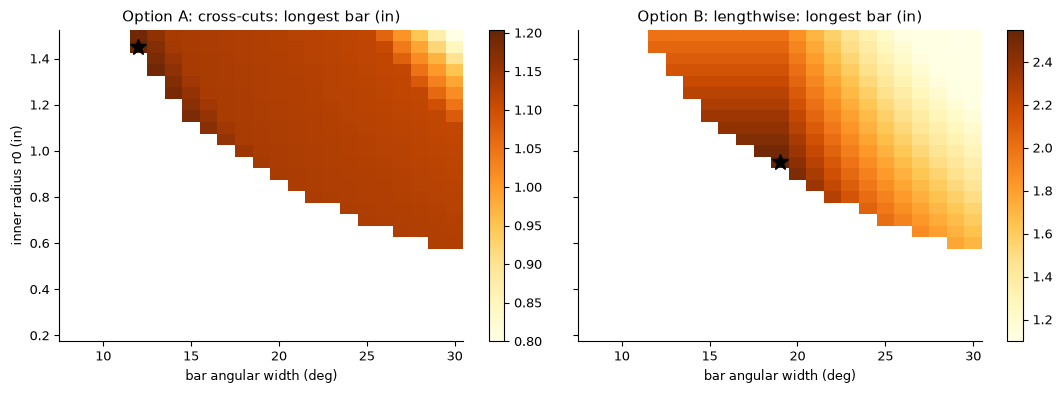

In [6]:
BAR_DEGS = np.arange(8, 30.1, 1.0)
R0S      = np.round(np.arange(0.20, 1.51, 0.05), 2)

def sweep(face):
    K = np.full((len(R0S), len(BAR_DEGS)), np.nan)
    for i, r0 in enumerate(R0S):
        for j, b in enumerate(BAR_DEGS):
            if inner_chord(r0, b) >= MIN_FEAT:
                K[i, j] = max_k(r0, b, face)
    return K

SW = {name: sweep(o["face"]) for name, o in OPTIONS.items()}
best = {}
for name, K in SW.items():
    i, j = np.unravel_index(np.nanargmax(K), K.shape)
    best[name] = dict(r0=R0S[i], bar_deg=BAR_DEGS[j], k=K[i, j])
    b = best[name]
    print(f"{name}: best k = {b['k']*100:.2f} in per 100 M lb at r0={b['r0']:.2f} in, bar width={b['bar_deg']:.0f} deg "
          f"-> longest bar {b['k']*VALS.max():.2f} in, shortest {b['k']*VALS.min():.2f} in")

fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (name, K) in zip(axs, SW.items()):
    im = ax.pcolormesh(BAR_DEGS, R0S, K * VALS.max(), shading="nearest", cmap="YlOrBr")
    b = best[name]; ax.plot(b["bar_deg"], b["r0"], "k*", ms=12)
    ax.set_title(f"Option {name}: longest bar (in)"); ax.set_xlabel("bar angular width (deg)")
    plt.colorbar(im, ax=ax)
axs[0].set_ylabel("inner radius r0 (in)")
plt.tight_layout(); plt.show()

## 6. Choose the design
We take the winning option, then round to friendly numbers (a scale you can measure with a ruler: *inches per 100 M lb*, rounded **down** to the nearest 0.05 in, and an inner radius rounded up) and re-verify.

In [7]:
choice = max(best, key=lambda n: best[n]["k"])
opt = OPTIONS[choice]
BAR_DEG = float(best[choice]["bar_deg"])
R0 = float(np.ceil(best[choice]["r0"] / 0.05) * 0.05)
while inner_chord(R0, BAR_DEG) < MIN_FEAT: R0 += 0.05
K = max_k(R0, BAR_DEG, opt["face"])
IN_PER_100 = np.floor(K * 100 / 0.05) * 0.05            # inches per 100 M lb
K = IN_PER_100 / 100
THICK = opt["thick"]; FACE = opt["face"]
print(f"Chosen: Option {choice}\n  bar width {BAR_DEG:.0f} deg (gap {PITCH-BAR_DEG:.0f} deg), inner radius {R0:.2f} in, inner chord {inner_chord(R0, BAR_DEG):.2f} in")
print(f"  scale: {IN_PER_100:.2f} in per 100 M lb  (50 M lb = {IN_PER_100/2:.3f} in)")
print(f"  slice thickness {THICK:.3f} in; chart outer radius {R0 + K*VALS.max():.2f} in")

def bar_geom(i):
    return dict(r_in=R0, r_out=R0 + K * VALS[i], v=VALS[i])

Chosen: Option B: lengthwise
  bar width 19 deg (gap 11 deg), inner radius 0.95 in, inner chord 0.31 in
  scale: 1.10 in per 100 M lb  (50 M lb = 0.550 in)
  slice thickness 0.297 in; chart outer radius 3.42 in


## 7. Verify every month, and see how much butter each bar uses
For each month: best rotation inside its slice (rotation 0° = bar lies along the slice's long edge, easiest to cut, preferred when it fits), the bounding box, spare room, and the share of the slice's volume that becomes sculpture.

In [8]:
Lu, Wu = usable(FACE)
rows, PLACE = [], {}
for i, m in enumerate(MONTHS):
    g = bar_geom(i)
    pts = sector_pts(g["r_in"], g["r_out"], BAR_DEG / 2)
    r, w, h = fit_ratio(pts, Lu, Wu)
    ok_idx = np.where(r <= 1)[0]
    idx = 0 if r[0] <= 1 else (ok_idx[np.argmin(r[ok_idx])] if len(ok_idx) else int(r.argmin()))
    PLACE[m] = dict(phi=PHI[idx], w=w[idx], h=h[idx], fits=bool(r[idx] <= 1))
    area = np.deg2rad(BAR_DEG) / 2 * (g["r_out"]**2 - g["r_in"]**2)
    rows.append(dict(month=m, mean_Mlb=round(g["v"], 1), bar_len_in=round(g["r_out"] - g["r_in"], 2), outer_R_in=round(g["r_out"], 2),
                     rot_deg=round(float(np.rad2deg(PHI[idx])), 1), bbox=f"{w[idx]:.2f} x {h[idx]:.2f}",
                     spare_in=round(min(Lu - w[idx], Wu - h[idx]), 2),
                     slice_used_pct=round(100 * area * THICK / (FACE[0] * FACE[1] * THICK), 1), fits=PLACE[m]["fits"]))
report = pd.DataFrame(rows).set_index("month")
display(report)
ALL_FIT = bool(report["fits"].all())
print("ALL 12 BARS FIT:", ALL_FIT)

,mean_Mlb,bar_len_in,outer_R_in,rot_deg,bbox,spare_in,slice_used_pct,fits
month,,,,,,,,
Jan,135.0,1.48,2.43,0.0,1.50 x 0.80,0.35,14.0,True
Feb,144.7,1.59,2.54,0.0,1.60 x 0.84,0.31,15.5,True
Mar,150.9,1.66,2.61,0.0,1.67 x 0.86,0.29,16.5,True
Apr,162.3,1.78,2.73,0.0,1.80 x 0.90,0.25,18.4,True
May,184.1,2.03,2.98,0.0,2.04 x 0.98,0.17,22.2,True
Jun,212.9,2.34,3.29,0.0,2.36 x 1.09,0.06,27.7,True
Jul,224.3,2.47,3.42,0.0,2.48 x 1.13,0.02,30.1,True
Aug,215.5,2.37,3.32,0.0,2.38 x 1.10,0.05,28.3,True
Sep,198.7,2.19,3.14,0.0,2.20 x 1.04,0.11,24.9,True


ALL 12 BARS FIT: True


## 8. Preview: the assembled sculpture and the 12 slices
Both drawn in true inches. Left: assembled chart (top view). Right: each month's bar positioned inside its slice, as it will be on the cutting templates.

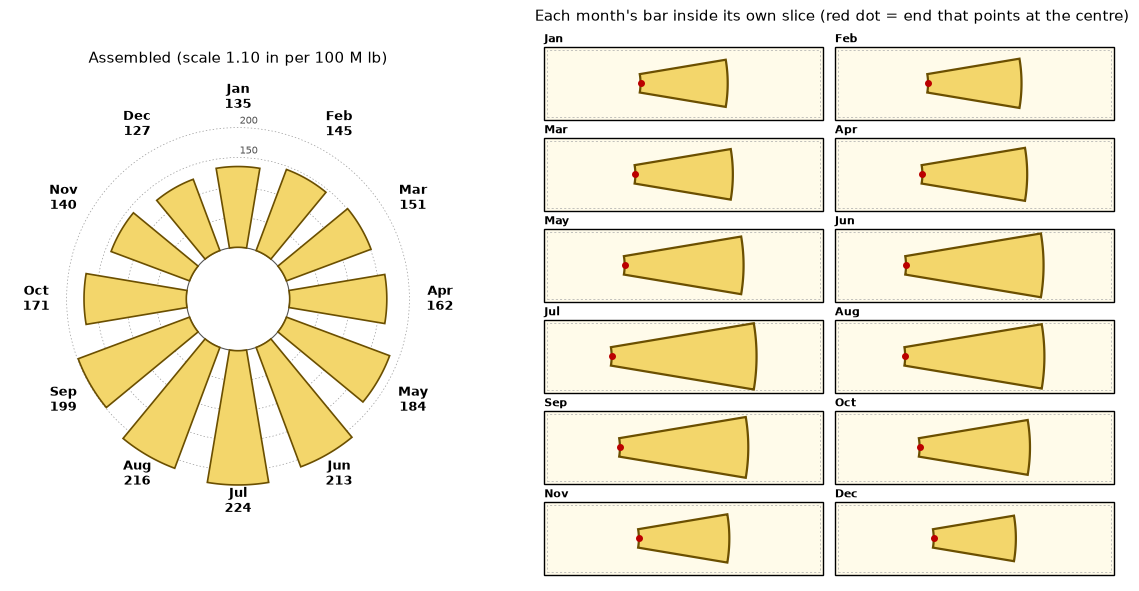

In [9]:
BUTTER, EDGE = "#F3D66B", "#6b4f00"

def sector_chart_poly(i, a_pad=0.0):
    g = bar_geom(i); th0 = PITCH * i
    a = np.linspace(-BAR_DEG/2, BAR_DEG/2, 60)
    ang = np.deg2rad(th0 + a)
    outer = np.c_[g["r_out"] * np.sin(ang), g["r_out"] * np.cos(ang)]
    inner = np.c_[g["r_in"] * np.sin(ang[::-1]), g["r_in"] * np.cos(ang[::-1])]
    return np.vstack([outer, inner])

TICKS = [50, 100, 150, 200]
def draw_assembled(ax, cx, cy, label_fs=9):
    ax.add_patch(plt.Circle((cx, cy), R0, fill=False, ec="#555", lw=0.8))
    for t in TICKS:
        r = R0 + K * t
        ax.add_patch(plt.Circle((cx, cy), r, fill=False, ec="#999", lw=0.5, ls=(0, (2, 3))))
        ax.text(cx + 0.03, cy + r + 0.03, f"{t}", fontsize=7, color="#555", ha="left", va="bottom")
    for i, m in enumerate(MONTHS):
        p = sector_chart_poly(i) + [cx, cy]
        ax.add_patch(Polygon(p, closed=True, fc=BUTTER, ec=EDGE, lw=1.2, zorder=3))
        th = np.deg2rad(PITCH * i); rl = R0 + K * (max(TICKS) + 40) + 0.12
        ax.text(cx + rl * np.sin(th), cy + rl * np.cos(th), f"{m}\n{VALS[i]:.0f}", ha="center", va="center", fontsize=label_fs, fontweight="bold")

def pieces_in_slab(ax, m, i, x0, y0, L, W, show_dims=True):
    """draw slice outline with lower-left corner (x0,y0) and the month's bar inside it"""
    ax.add_patch(Rectangle((x0, y0), L, W, fc="#FFFBEA", ec="k", lw=1.0))
    ax.add_patch(Rectangle((x0 + EDGE_MARGIN, y0 + EDGE_MARGIN), L - 2*EDGE_MARGIN, W - 2*EDGE_MARGIN, fill=False, ec="#aaa", lw=0.5, ls=(0, (3, 3))))
    g, pl = bar_geom(i), PLACE[m]
    pts = sector_pts(g["r_in"], g["r_out"], BAR_DEG / 2)
    c, s = np.cos(pl["phi"]), np.sin(pl["phi"])
    q = np.c_[pts[:, 0]*c - pts[:, 1]*s, pts[:, 0]*s + pts[:, 1]*c]
    q = q - [(q[:, 0].max() + q[:, 0].min())/2, (q[:, 1].max() + q[:, 1].min())/2] + [x0 + L/2, y0 + W/2]
    ax.add_patch(Polygon(q, closed=True, fc=BUTTER, ec=EDGE, lw=1.6, zorder=3))
    # mark the inner (towards-centre) end: centre of the inner edge
    inner_mid = np.array([g["r_in"] * np.cos(0), 0.0]) if g["r_in"] > 0 else np.zeros(2)
    ctr = np.array([(pts[:, 0] * c - pts[:, 1] * s).max() + (pts[:, 0] * c - pts[:, 1] * s).min(), (pts[:, 0] * s + pts[:, 1] * c).max() + (pts[:, 0] * s + pts[:, 1] * c).min()]) / 2
    im = np.array([inner_mid[0]*c - inner_mid[1]*s, inner_mid[0]*s + inner_mid[1]*c]) - ctr + [x0 + L/2, y0 + W/2]
    ax.plot(*im, marker="o", ms=4, color="#b00", zorder=5)
    return q

fig = plt.figure(figsize=(12, 6))
ax1 = fig.add_axes([0.02, 0.05, 0.38, 0.9]); ax1.set_aspect("equal"); ax1.axis("off")
lim = R0 + K * (max(TICKS) + 40) + 0.6
ax1.set_xlim(-lim, lim); ax1.set_ylim(-lim, lim); draw_assembled(ax1, 0, 0)
ax1.set_title(f"Assembled (scale {IN_PER_100:.2f} in per 100 M lb)")
ax2 = fig.add_axes([0.42, 0.03, 0.57, 0.92]); ax2.set_aspect("equal"); ax2.axis("off")
cols, rows_n = 2, 6
ax2.set_xlim(-0.1, cols*(FACE[0] + 0.2)); ax2.set_ylim(-0.1, rows_n*(FACE[1] + 0.3))
for i, m in enumerate(MONTHS):
    cidx, ridx = i % 2, i // 2
    x0, y0 = cidx*(FACE[0] + 0.2), (rows_n - 1 - ridx)*(FACE[1] + 0.3)
    pieces_in_slab(ax2, m, i, x0, y0, *FACE)
    ax2.text(x0, y0 + FACE[1] + 0.03, m, fontsize=8, fontweight="bold", va="bottom")
ax2.set_title("Each month's bar inside its own slice (red dot = end that points at the centre)")
plt.show()

## 9. Print-ready 1:1 templates
`figures/butter_sculpture_patterns.pdf` (US Letter, vectors drawn at **true size**; print at **"Actual size / 100 %"**, not "fit to page"):

1. **Calibration & cut guide.** Rulers to confirm the print scale, and an end-on template with the 3 cut lines for slicing a stick into 4 slices.
2. **Assembled chart.** Full size, so you can lay the finished bars on it (or place it under wax paper).
3. **Month templates (2 pages).** Each month's slice outline with its bar outline inside. Lay the printout (or wax paper traced from it) on the slice and cut around the bar. The red dot marks the end that points at the centre.

Tip: tape the printout under a sheet of wax/parchment paper and trace with a toothpick or the tip of a knife; do not put paper straight on the butter.

wrote figures/butter_sculpture_patterns.pdf


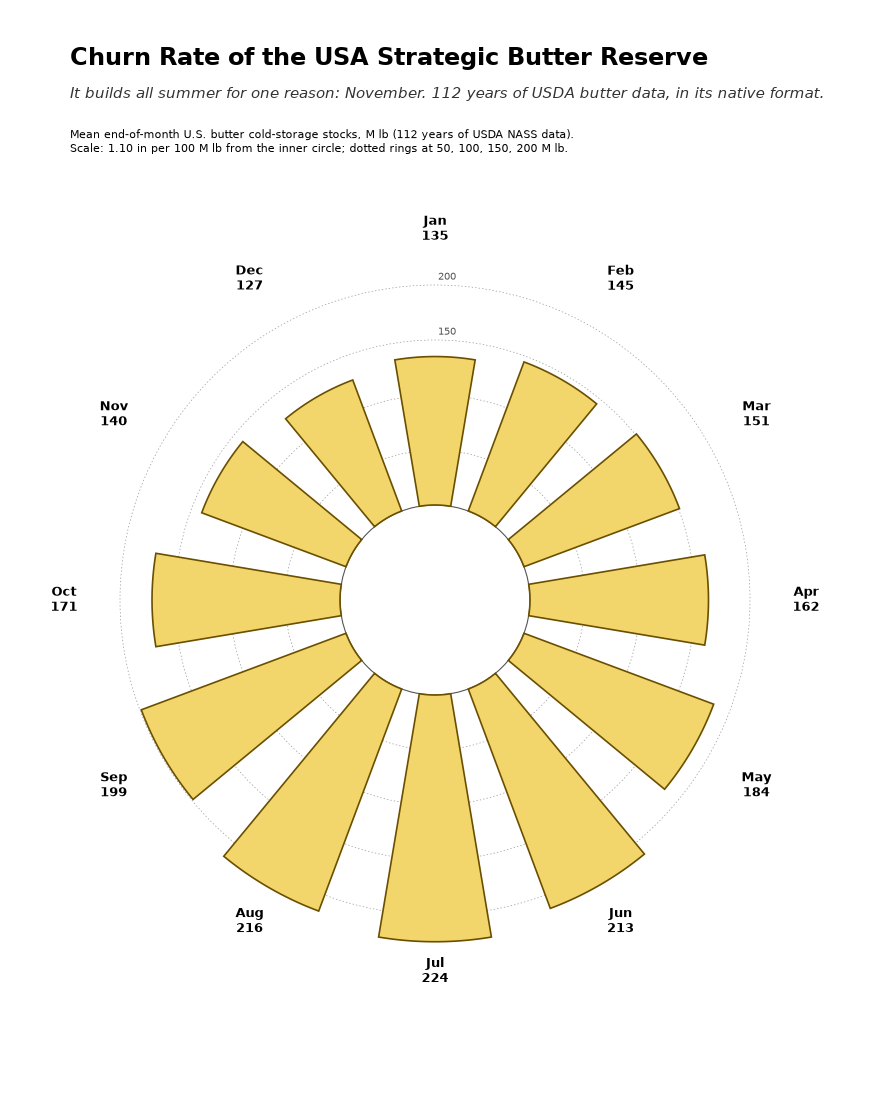

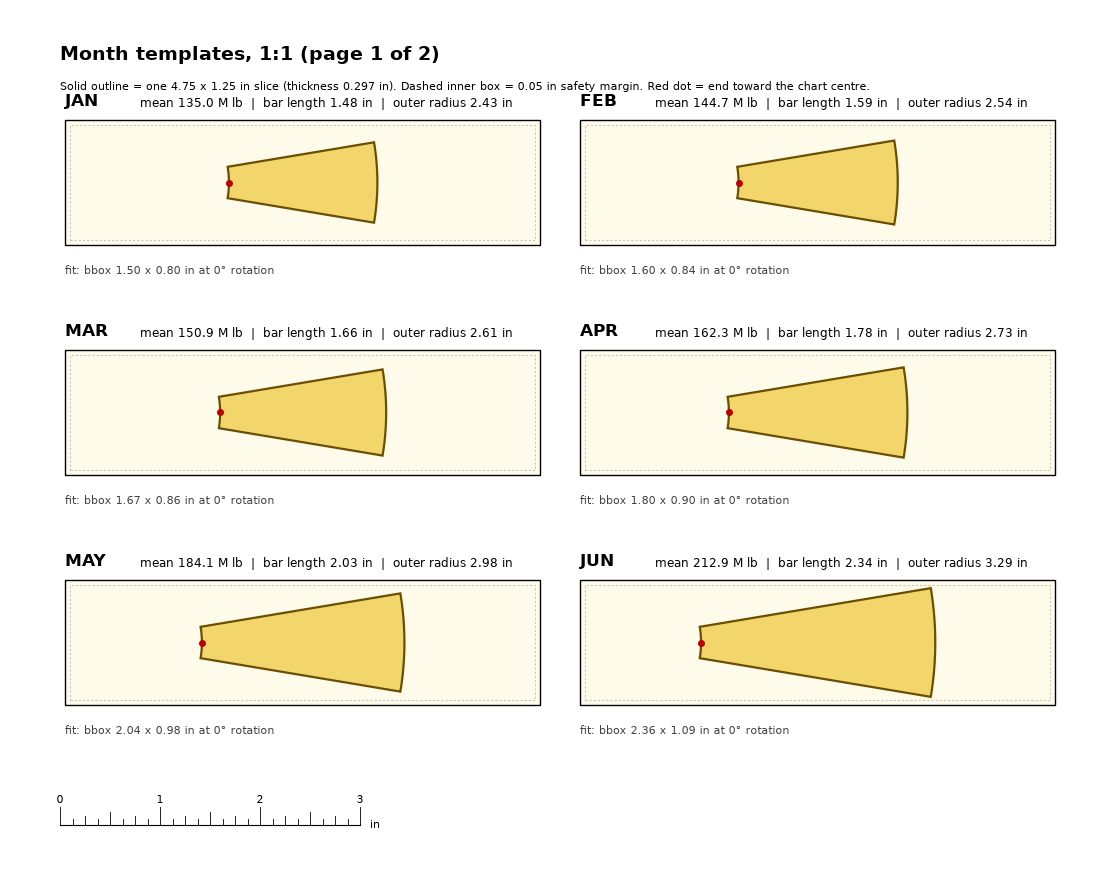

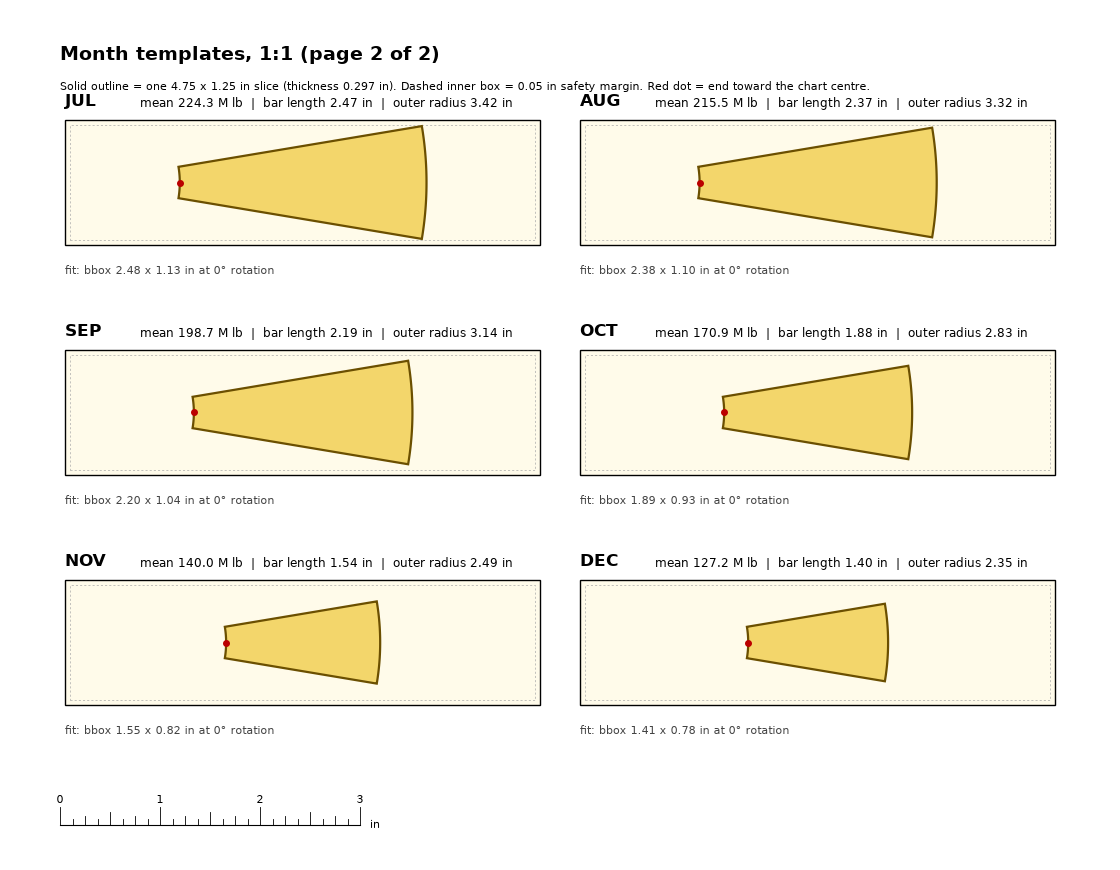

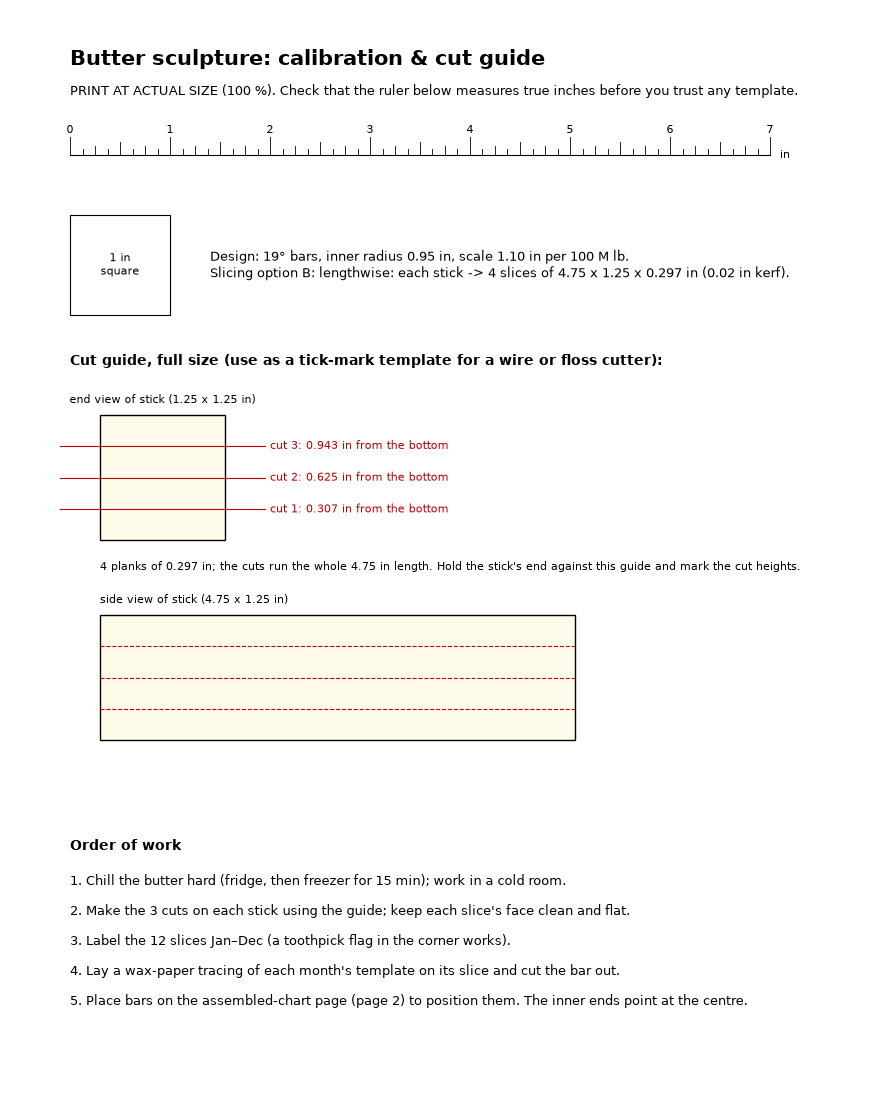

In [10]:
def new_page(W, H):
    fig = plt.figure(figsize=(W, H))
    ax = fig.add_axes([0, 0, 1, 1]); ax.set_xlim(0, W); ax.set_ylim(0, H); ax.set_aspect("equal"); ax.axis("off")
    return fig, ax

def ruler(ax, x0, y, length, ticks=1/8):
    ax.plot([x0, x0 + length], [y, y], "k", lw=0.8)
    for n in range(int(round(length / ticks)) + 1):
        x = x0 + n * ticks
        big = n % 8 == 0; half = n % 4 == 0; q = n % 2 == 0
        ax.plot([x, x], [y, y + (0.18 if big else 0.13 if half else 0.09 if q else 0.06)], "k", lw=0.6)
        if big: ax.text(x, y + 0.22, str(n // 8), ha="center", fontsize=8)
    ax.text(x0 + length + 0.1, y, "in", fontsize=8, va="center")

pages = []

# ---- page 1: calibration + cut guide (portrait) ----
fig, ax = new_page(8.5, 11); pages.append(fig)
ax.text(0.6, 10.45, "Butter sculpture: calibration & cut guide", fontsize=15, fontweight="bold")
ax.text(0.6, 10.15, "PRINT AT ACTUAL SIZE (100 %). Check that the ruler below measures true inches before you trust any template.", fontsize=9)
ruler(ax, 0.6, 9.55, 7.0)
ax.add_patch(Rectangle((0.6, 7.95), 1, 1, fill=False, ec="k", lw=0.8)); ax.text(1.1, 8.45, "1 in\nsquare", ha="center", va="center", fontsize=8)
ax.text(2.0, 8.45, f"Design: {BAR_DEG:.0f}° bars, inner radius {R0:.2f} in, scale {IN_PER_100:.2f} in per 100 M lb.\n"
        f"Slicing option {choice}: each stick -> {SLICES} slices of {FACE[0]:.2f} x {FACE[1]:.2f} x {THICK:.3f} in ({KERF} in kerf).", fontsize=9, va="center")

# end-on cut guide (lengthwise: 3 cuts across the 1.25 in height) or side guide (cross-cuts)
ax.text(0.6, 7.45, "Cut guide, full size (use as a tick-mark template for a wire or floss cutter):", fontsize=10, fontweight="bold")
if choice.startswith("B"):
    gx, gy = 0.9, 5.7
    ax.add_patch(Rectangle((gx, gy), STICK_W, STICK_H, fc="#FFFBEA", ec="k", lw=1)); ax.text(gx + STICK_W/2, gy + STICK_H + 0.12, "end view of stick (1.25 x 1.25 in)", ha="center", fontsize=8)
    cuts = [j*(THICK + KERF) - KERF/2 for j in range(1, SLICES)]
    for j, c in enumerate(cuts, 1):
        ax.plot([gx - 0.4, gx + STICK_W + 0.4], [gy + c, gy + c], color="#b00", lw=0.8)
        ax.text(gx + STICK_W + 0.45, gy + c, f"cut {j}: {c:.3f} in from the bottom", fontsize=8, va="center", color="#b00")
    ax.text(gx, gy - 0.3, f"4 planks of {THICK:.3f} in; the cuts run the whole 4.75 in length. Hold the stick's end against this guide and mark the cut heights.", fontsize=8)
    sx, sy = 0.9, 3.7
    ax.add_patch(Rectangle((sx, sy), STICK_L, STICK_H, fc="#FFFBEA", ec="k", lw=1)); ax.text(sx, sy + STICK_H + 0.12, "side view of stick (4.75 x 1.25 in)", fontsize=8)
    for c in cuts: ax.plot([sx, sx + STICK_L], [sy + c, sy + c], color="#b00", lw=0.8, ls="--")
else:
    sx, sy = 0.9, 5.5
    ax.add_patch(Rectangle((sx, sy), STICK_L, STICK_H, fc="#FFFBEA", ec="k", lw=1)); ax.text(sx, sy + STICK_H + 0.12, "side view of stick (4.75 x 1.25 in)", fontsize=8)
    cuts = [j*(THICK + KERF) - KERF/2 for j in range(1, SLICES)]
    for j, c in enumerate(cuts, 1):
        ax.plot([sx + c, sx + c], [sy - 0.2, sy + STICK_H + 0.2], color="#b00", lw=0.8)
        ax.text(sx + c, sy - 0.3, f"{c:.3f}", fontsize=7, ha="center", color="#b00")
ax.text(0.6, 2.6, "Order of work", fontsize=10, fontweight="bold")
steps = ["1. Chill the butter hard (fridge, then freezer for 15 min); work in a cold room.",
         "2. Make the 3 cuts on each stick using the guide; keep each slice's face clean and flat.",
         "3. Label the 12 slices Jan–Dec (a toothpick flag in the corner works).",
         "4. Lay a wax-paper tracing of each month's template on its slice and cut the bar out.",
         "5. Place bars on the assembled-chart page (page 2) to position them. The inner ends point at the centre."]
for k, t in enumerate(steps): ax.text(0.6, 2.25 - 0.3*k, t, fontsize=9)

# ---- page 2: assembled chart 1:1 (portrait) ----
fig, ax = new_page(8.5, 11); pages.append(fig)
ax.text(0.6, 10.45, "Churn Rate of the USA Strategic Butter Reserve", fontsize=17, fontweight="bold")
ax.text(0.6, 10.12, "It builds all summer for one reason: November. 112 years of USDA butter data, in its native format.", fontsize=10.5, style="italic", color="#333")
ax.text(0.6, 9.82, f"Mean end-of-month U.S. butter cold-storage stocks, M lb ({raw['year'].nunique()} years of USDA NASS data).\n"
        f"Scale: {IN_PER_100:.2f} in per 100 M lb from the inner circle; dotted rings at 50, 100, 150, 200 M lb.", fontsize=8, va="top")
draw_assembled(ax, 4.25, 5.1)

# ---- pages 3-4: month templates (landscape) ----
LW, LH = 11, 8.5
def template_page(idxs, pageno):
    fig, ax = new_page(LW, LH); pages.append(fig)
    ax.text(0.5, LH - 0.5, f"Month templates, 1:1 (page {pageno} of 2)", fontsize=14, fontweight="bold")
    ax.text(0.5, LH - 0.8, f"Solid outline = one {FACE[0]:.2f} x {FACE[1]:.2f} in slice (thickness {THICK:.3f} in). Dashed inner box = {EDGE_MARGIN} in safety margin. Red dot = end toward the chart centre.", fontsize=8)
    xs = [(LW - 2*FACE[0] - 0.4) / 2 + c*(FACE[0] + 0.4) for c in range(2)]
    for n, i in enumerate(idxs):
        m = MONTHS[i]; cidx, ridx = n % 2, n // 2
        x0, y0 = xs[cidx], LH - 2.35 - ridx * 2.3
        pieces_in_slab(ax, m, i, x0, y0, *FACE)
        g = bar_geom(i)
        ax.text(x0, y0 + FACE[1] + 0.1, f"{m.upper()}", fontsize=12, fontweight="bold", va="bottom")
        ax.text(x0 + 0.75, y0 + FACE[1] + 0.1, f"mean {VALS[i]:.1f} M lb  |  bar length {g['r_out']-g['r_in']:.2f} in  |  outer radius {g['r_out']:.2f} in", fontsize=8.5, va="bottom")
        ax.text(x0, y0 - 0.2, f"fit: bbox {PLACE[m]['w']:.2f} x {PLACE[m]['h']:.2f} in at {np.rad2deg(PLACE[m]['phi']):.0f}° rotation", fontsize=8, va="top", color="#444")
    ruler(ax, 0.5, 0.35, 3.0)
template_page(range(0, 6), 1)
template_page(range(6, 12), 2)

with PdfPages(FIGS / "butter_sculpture_patterns.pdf", metadata={"Title": "Butter sculpture templates (1:1)"}) as pdf:
    for f in pages: pdf.savefig(f)
print("wrote", FIGS / "butter_sculpture_patterns.pdf")
for f in pages[:1]: plt.figure(f.number)
plt.show()

In [11]:
total_in3 = N_STICKS * STICK_L * STICK_W * STICK_H
used_in3 = sum(np.deg2rad(BAR_DEG) / 2 * (bar_geom(i)["r_out"]**2 - R0**2) * THICK for i in range(12))
display(Markdown(f"""
## 10. Verdict
**{"Yes, it is possible." if ALL_FIT else "No, not with these constraints."}**

- **Slicing:** cut each stick **{"lengthwise into 4 planks" if choice.startswith("B") else "across into 4 chunks"}** ({FACE[0]:.2f} x {FACE[1]:.2f} x {THICK:.3f} in each). The best chart from the other option ({[n for n in best if n != choice][0]}) only reaches a scale of {best[[n for n in best if n != choice][0]]["k"]*100:.2f} in per 100 M lb, vs {IN_PER_100:.2f} here.
- **Chart:** {BAR_DEG:.0f}° bars with a {R0:.2f} in inner radius, scale {IN_PER_100:.2f} in per 100 M lb ⇒ bars run from {K*VALS.min():.2f} in (Dec, {VALS.min():.0f} M lb) to {K*VALS.max():.2f} in (Jul, {VALS.max():.0f} M lb); assembled diameter {2*(R0+K*VALS.max()):.1f} in.
- **What limits it:** the width of the slice, not the length. A sector's far end is about 2·R·sin(half-angle) wide, so the longest bar's width has to fit across the slice's {FACE[1]:.2f} in dimension.
- **Butter budget:** only {100*used_in3/total_in3:.0f} % of the {N_STICKS} sticks' volume ends up in the bars; the offcuts are free for practice or for building a base.
- **Caveats:** measure the real sticks and update the first cell (sticks vary by a few %); the competition rules may restrict tools or reuse of offcuts; with `R0 > 0` the bars do not touch each other, so they need a base to sit on.
"""))


## 10. Verdict
**Yes, it is possible.**

- **Slicing:** cut each stick **lengthwise into 4 planks** (4.75 x 1.25 x 0.297 in each). The best chart from the other option (A: cross-cuts) only reaches a scale of 0.54 in per 100 M lb, vs 1.10 here.
- **Chart:** 19° bars with a 0.95 in inner radius, scale 1.10 in per 100 M lb ⇒ bars run from 1.40 in (Dec, 127 M lb) to 2.47 in (Jul, 224 M lb); assembled diameter 6.8 in.
- **What limits it:** the width of the slice, not the length. A sector's far end is about 2·R·sin(half-angle) wide, so the longest bar's width has to fit across the slice's 1.25 in dimension.
- **Butter budget:** only 19 % of the 3 sticks' volume ends up in the bars; the offcuts are free for practice or for building a base.
- **Caveats:** measure the real sticks and update the first cell (sticks vary by a few %); the competition rules may restrict tools or reuse of offcuts; with `R0 > 0` the bars do not touch each other, so they need a base to sit on.
